In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

data = pd.read_csv("Fake.csv")

print(data.head())
print("Dataset Shape:", data.shape)
print(data.columns)

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  
Dataset Shape: (23481, 4)
Index(['title', 'text', 'subject', 'date'], dtype='str')


In [2]:
data = data.dropna(
    subset=["text", "subject"]
).copy()

data["text"] = data["text"].astype(str).str.strip()
data["subject"] = data["subject"].astype(str).str.strip()

data = data[
    (data["text"] != "") &
    (data["subject"] != "")
]

print("Missing Values:")
print(data[["text", "subject"]].isnull().sum())

print("Final Shape:", data.shape)

Missing Values:
text       0
subject    0
dtype: int64
Final Shape: (22851, 4)


subject
News               9050
politics           6433
left-news          4309
Government News    1498
US_News             783
Middle-east         778
Name: count, dtype: int64


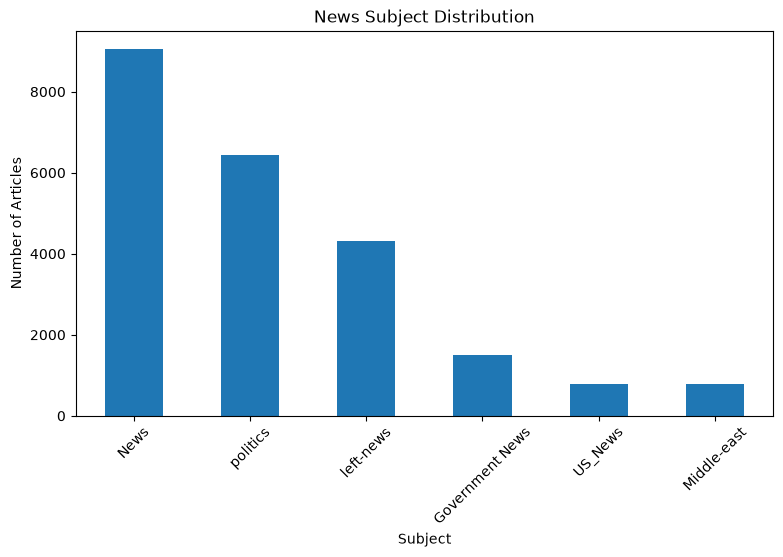

In [3]:
print(data["subject"].value_counts())

data["subject"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("News Subject Distribution")
plt.xlabel("Subject")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

In [4]:
X = data["text"]
y = data["subject"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (22851,)
Target: (22851,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 18280
Testing Records: 4571


In [6]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training Matrix:", X_train_tfidf.shape)
print("Testing Matrix:", X_test_tfidf.shape)

Training Matrix: (18280, 5000)
Testing Matrix: (4571, 5000)


In [7]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model Training Completed!")

Model Training Completed!


In [8]:
y_pred = model.predict(X_test_tfidf)

print("Actual Subjects:")
print(y_test.head().tolist())

print("Predicted Subjects:")
print(y_pred[:5].tolist())

Actual Subjects:
['politics', 'News', 'News', 'News', 'News']
Predicted Subjects:
['politics', 'News', 'News', 'News', 'News']


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Model Accuracy: 61.54 %

Classification Report:
                 precision    recall  f1-score   support

Government News       0.27      0.08      0.12       300
    Middle-east       0.12      0.11      0.12       155
           News       0.96      0.98      0.97      1810
        US_News       0.15      0.15      0.15       157
      left-news       0.25      0.17      0.20       862
       politics       0.47      0.64      0.54      1287

       accuracy                           0.62      4571
      macro avg       0.37      0.35      0.35      4571
   weighted avg       0.59      0.62      0.59      4571



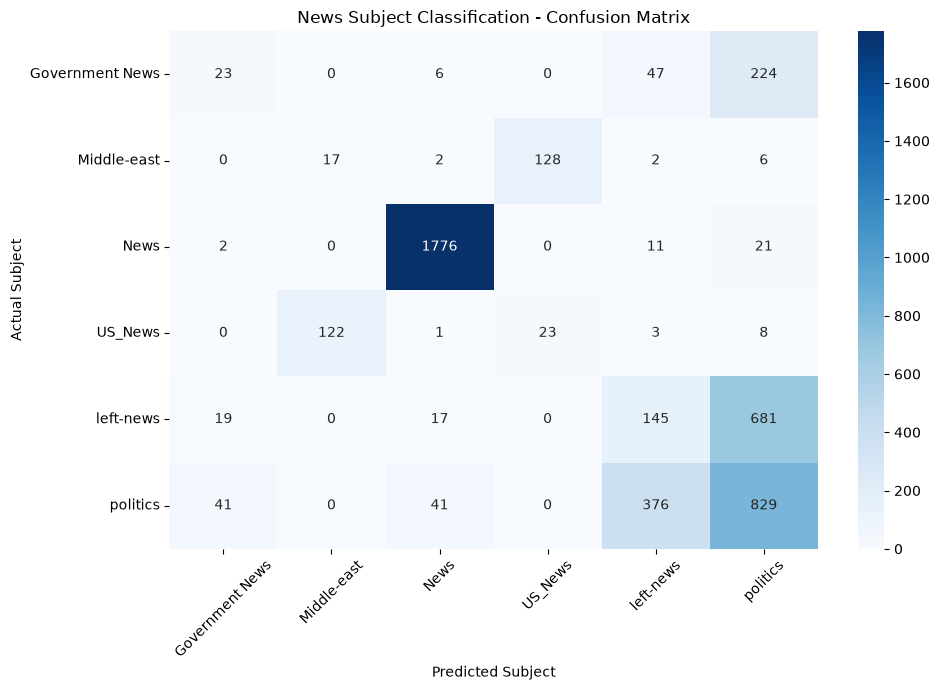

In [10]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Subject")
plt.ylabel("Actual Subject")
plt.title("News Subject Classification - Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
news = input("Enter News Text: ")

news_tfidf = tfidf.transform([news])

prediction = model.predict(news_tfidf)

print("Predicted News Subject:", prediction[0])

Enter News Text: CCCCCCCCCC
Predicted News Subject: politics
